In [2]:
import pandas as pd
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.optimize import curve_fit
import matplotlib.colors as mcolors
from matplotlib.colors import to_hex
from IPython.display import HTML, display

# BaCBM2-substrate interactions 
Chemical shift perturbations (CSP), intensity changes, linewidth estimation for BaCBM2 with BHET and nanoPET. 
Uses data from CCPN. 15N-HSQC spectra. 
Writes scripts for coloring in pymol (folder: pymol_csp_i_lw)

## Chemical shift mapping

In [28]:
def get_CSP(filepath, seq_corr): #seq_corr: Ba=7, Sc=3
    df = pd.read_excel(filepath) 
    df = df[~df.astype(str).apply(lambda row: row.str.contains('@')).any(axis=1)] # remove unassigned residues
    df['residue'] = df['nmrResidueCode'].astype(int)-seq_corr #Get correct sequence number
    df = df.sort_values(by="residue")
    df_main = df[df['nmrAtomNames'] == 'H,N']

    return df_main

def get_CSP_sc(filepath):  #sidechains
    df = pd.read_excel(filepath) 
    df['residue'] = df['nmrResidueCode']
    df = df.sort_values(by="residue")
    df['residue'] = df['nmrResidueCode'].astype(str)
    df_main = df[df['nmrAtomNames'] == 'HE1,NE1']

    return df_main

def get_colors(df, remove_first=False):
    y = df['DeltaDelta']
    x = df['residue']
    if remove_first == True:
        y = y[2:]
        x = x[2:]
    
    avg = y.mean()
    res_above_avg = x[y > avg].tolist()
    std = y.std()
    res_above_avg_std = x[y > (avg + std)].tolist()

    #color map
    cmap = plt.get_cmap("viridis_r")
    #define y range for color map
    norm = mcolors.Normalize(vmin=y.min(), vmax=y.max())
    colors = cmap(norm(y))
    show_colored_sequence_2(x, y, colors, remove_first)
    return cmap, norm, colors, avg, std

def show_colored_sequence_2(x, y, colors, remove_first = False):
    if remove_first == False:
        sequence = 'GSCMAVYSVENSWSGGFQGSVEVMNHGTEPLNGWAVQWQPGGGTTLGGVWNGSLTSGSDGTVTVRNVDHNRVVPPDGSVTFGFTATSTGNDFPVDSIGCVAP' #ScCBM2
    elif remove_first == True:
        sequence = 'ATFSVTSNWGSGYNFSIVIKNSGTTPIKNWKLEFDYNGNLTQVWDSKISSKINNHYVITNAGWNGEIPPGGSITIGGAGTGTPAELVNASISEN' #BaCBM2
    else:
        raise ValueError("plot_title must contain 'Sc' or 'Ba'")

    colors = [to_hex(c) for c in colors]

    # Create dictionary: residue number -> color
    color_dict = dict(zip(x, colors))

    html_seq = ""

    for i, aa in enumerate(sequence, start=1):
        # Use color if residue exists in x, otherwise grey
        color = color_dict.get(i, "#B5B3B3")

        html_seq += (
            f"<span style='color:{color}; font-family:monospace;'>"
            f"{aa}</span>"
        )

    display(HTML(html_seq))

def plot_CSP(df, label, ax, remove_first=False):
    y = df['DeltaDelta']
    x = df['residue']
    if remove_first == True:
        y = y[2:]
        x = x[2:]
    
    avg = y.mean()
    res_above_avg = x[y > avg].tolist()
    std = y.std()
    res_above_avg_std = x[y > (avg + std)].tolist()

    #Pymol show sticks:
    print(f"\n------------{label}------------------")
    print(f"Average CSP: {avg:.4f}")
    print(f"Std Dev:     {std:.4f}")
    
    print("\nResidues above average:")
    print(res_above_avg)
    print("Residues above average + std:")
    print(res_above_avg_std)
    
    # PyMOL selections
    print("\nPyMOL commands:")
    print("select high_csp_" + label + ", resi " + "+".join(map(str, res_above_avg)))
    print("select high_csp_std_" + label + ", resi " + "+".join(map(str, res_above_avg_std)) + "\n")

    #color map
    cmap, norm, colors, avg, std = get_colors(df, remove_first)

    #pymol coloring
    rgb_colors = {}
    for resi, value in zip(x, y):
        r, g, b, _ = cmap(norm(value))
        rgb_colors[int(resi)] = (r, g, b)
        
    label = label.replace(' ', '_')
    filename = f"pymol_csp_i_lw/pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}\n")

        f.write(f"color white, {label}\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label} and resi {resi}\n"
            )

        f.write(f"select high_{label}, {label} and resi {'+'.join(map(str, res_above_avg))}\n")
        f.write(f"select high_std_{label}, {label} and resi {'+'.join(map(str, res_above_avg_std))}\n")

    label = label.replace('_', ' ')
    ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8)
    ax.axhline(avg+std, color = cmap(norm(avg+std)), linewidth = 0.8, linestyle = '--')
    ax.scatter(x, y, c= colors, alpha = 1, label = label, s = 10)
    ax.set_ylabel('$\Delta \delta$')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    #ax.set_ylim((0,0.03))
    #ax.set_xlim((0,105))
    ax.set_title(label = label, fontsize = 8)

def plot_CSP_sc(df, df_sc, ax, remove_first=False):
    cmap, norm, colors, avg, std = get_colors(df, remove_first)
    y = df_sc['DeltaDelta']
    x = df_sc['residue']
    
    ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8)
    ax.axhline(avg+std, color = cmap(norm(avg+std)), linewidth = 0.8, linestyle = '--')
    ax.scatter(x, y, c= cmap(norm(y)), alpha = 1, s = 10)




------------BaCBM2 BHET------------------
Average CSP: 0.0031
Std Dev:     0.0022

Residues above average:
[1, 8, 9, 10, 11, 12, 14, 15, 16, 24, 38, 41, 43, 44, 45, 49, 50, 58, 62, 63, 64, 70, 74, 76, 78, 80, 82, 84, 86, 88]
Residues above average + std:
[8, 9, 10, 11, 49, 63, 70, 82, 84]

PyMOL commands:
select high_csp_BaCBM2 BHET, resi 1+8+9+10+11+12+14+15+16+24+38+41+43+44+45+49+50+58+62+63+64+70+74+76+78+80+82+84+86+88
select high_csp_std_BaCBM2 BHET, resi 8+9+10+11+49+63+70+82+84




------------BaCBM2 nanoPET------------------
Average CSP: 0.0018
Std Dev:     0.0020

Residues above average:
[20, 21, 22, 23, 24, 29, 30, 31, 45, 58, 63, 66, 67, 70, 75, 78, 87, 91, 92, 94]
Residues above average + std:
[20, 22, 23, 24, 29, 30, 45, 91]

PyMOL commands:
select high_csp_BaCBM2 nanoPET, resi 20+21+22+23+24+29+30+31+45+58+63+66+67+70+75+78+87+91+92+94
select high_csp_std_BaCBM2 nanoPET, resi 20+22+23+24+29+30+45+91



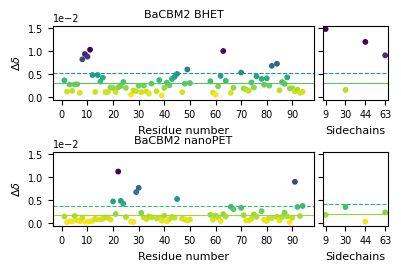

In [29]:
# Plot CSPs:
plt.rcParams.update({
    "font.size": 8,        # base font size
    "axes.labelsize": 8,   # axis labels
    "xtick.labelsize": 7,  # x tick labels
    "ytick.labelsize": 7,  # y tick labels
    "legend.fontsize": 8,  # legend
})

width_mm = 110
width_in = width_mm / 25.4 
height_in = width_in*0.6


fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = True, gridspec_kw={'width_ratios': [4, 1]})
fig.subplots_adjust(hspace=0.7)
fig.subplots_adjust(wspace=0.05)
ax[0,0].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[0,0].set_xlabel('Residue number')
ax[1,0].set_xlabel('Residue number')
ax[0,1].set_xlabel('Sidechains')
ax[1,1].set_xlabel('Sidechains')
ax[0,0].yaxis.set_major_locator(ticker.MultipleLocator(0.005))

filepath = 'CCPN_CSP/Data/BHET_ccpnTable.xlsx'
filepath_sc = 'CCPN_CSP/Data/SC_BHET_ccpnTable.xlsx'
plot_CSP(get_CSP(filepath, 7), 'BaCBM2 BHET', ax[0,0], remove_first=True)
plot_CSP_sc(get_CSP(filepath, 7), get_CSP_sc(filepath_sc), ax[0,1])

filepath = 'CCPN_CSP/Data/nanoPET_ccpnTable.xlsx'
filepath_sc = 'CCPN_CSP/Data/SC_nanoPET_ccpnTable.xlsx'
plot_CSP(get_CSP(filepath, 7), 'BaCBM2 nanoPET', ax[1,0], remove_first=True)
plot_CSP_sc(get_CSP(filepath, 7), get_CSP_sc(filepath_sc), ax[1,1])

plt.savefig('Plots/BaCBM2_csp_sc.svg', bbox_inches='tight')

## Intensity

In [30]:
def filter_df(filepath, seq_corr):   #seq_corr: Ba=7, Sc=3
    df = pd.read_excel(filepath)
    filtered_df = df[df['Assign F1'].str.endswith('H', na=False)].copy()
    filtered_df['res'] = filtered_df['Assign F1'].str.split('.').str[-3].astype(int) - seq_corr
    filtered_df = filtered_df.sort_values(by="res")
    
    return filtered_df

def filter_df_sc(filepath):  #sidechains
    df = pd.read_excel(filepath)
    filtered_df = df[df['Assign F1'].str.endswith('HE1', na=False)].copy()
    filtered_df['res'] = filtered_df['Assign F1'].str.split('.').str[-3].astype(int)
    filtered_df = filtered_df.sort_values(by="res")
    filtered_df['res'] = filtered_df['res'].astype(str)
    
    return filtered_df

#calculate intensity changes
def calc_deltaI(dfP, dfPL):
    # Keep only residues present in both dataframes
    df = pd.merge(
        dfP[['res', 'Height', 'Volume', 'LW F1']],
        dfPL[['res', 'Height', 'Volume', 'LW F1']],
        on='res',
        how='inner',
        suffixes=('_P', '_PL')
    )
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    
    df['deltaH'] = df['Height_P'] - df['Height_PL']    #absolute deltaI
    std_deltaH = df['deltaH'].std()
    avg_deltaH = df['deltaH'].mean()

    df['deltaH_pct'] = df['deltaH'] / df['Height_P']   #relative deltaI
    std_deltaH_pct = df['deltaH_pct'].std()
    avg_deltaH_pct = df['deltaH_pct'].mean()

    df['deltaV'] = df['Volume_P'] - df['Volume_PL']    #absolute deltaV
    std_deltaV = df['deltaV'].std()
    avg_deltaV = df['deltaV'].mean()

    df['deltaV_pct'] = df['deltaV'] / df['Volume_P']   #relative deltaV
    std_deltaV_pct = df['deltaV_pct'].std()
    avg_deltaV_pct = df['deltaV_pct'].mean()

    df['deltaLW'] = df['LW F1_P'] - df['LW F1_PL']    #absolute delta LW
    std_deltaLW = df['deltaLW'].std()
    avg_deltaLW = df['deltaLW'].mean()

    df['deltaLW_pct'] = df['deltaLW'] / df['LW F1_P']   #relative deltaV
    std_deltaLW_pct = df['deltaLW_pct'].std()
    avg_deltaLW_pct = df['deltaLW_pct'].mean()

    std = [std_deltaH, std_deltaH_pct, std_deltaV, std_deltaV_pct, std_deltaLW, std_deltaLW_pct]
    avg = [avg_deltaH, avg_deltaH_pct, avg_deltaV, avg_deltaV_pct, avg_deltaLW, avg_deltaLW_pct]

    return df, std, avg

In [31]:
#Dataframes from CCPN data

#main chains
df_Ba_free = filter_df('CCPN_CSP/Data/BaCBM2_free_intensity.xlsx', 7)
df_Ba_BHET = filter_df('CCPN_CSP/Data/BaCBM2_BHET_intensity.xlsx', 7)
df_Ba_nPET = filter_df('CCPN_CSP/Data/BaCBM2_nanoPET_intensity.xlsx', 7)

#sidechains
df_Ba_free_SC = filter_df_sc('CCPN_CSP/Data/SC_BaCBM2_free_intensity.xlsx')
df_Ba_BHET_SC = filter_df_sc('CCPN_CSP/Data/SC_BaCBM2_BHET_intensity.xlsx')
df_Ba_nPET_SC = filter_df_sc('CCPN_CSP/Data/SC_BaCBM2_nanoPET_intensity.xlsx')


In [32]:
def plot_deltaI(dfP, dfPL, ax, label):
    df, std, avg = calc_deltaI(dfP, dfPL)

    x = df['res']
    y = df['deltaH_pct']
    std = std[1]
    avg = avg[1]

    res_above_avg_std = x[y > (avg + std)].tolist()
    res_above_avg = x[y > avg].tolist()

        #Pymol show sticks:
    print(f"\n------------ Relative intensity change ------------------")
    print(f"Average deltaI: {avg:.4f}")
    print(f"Std Dev:     {std:.4f}")

    print("Residues above average + std:")
    print(res_above_avg_std)
    print("\nPyMOL commands:")
    print("select high_csp_std_" + label + ", resi " + "+".join(map(str, res_above_avg_std)) + "\n")

    #color map
    cmap = plt.get_cmap("Blues")
    #define y range for color map
    norm = mcolors.Normalize(vmin=y.min(), vmax=y.max())
    colors = cmap(norm(y))

    #pymol coloring
    rgb_colors = {}
    for resi, value in zip(x, y):
        r, g, b, _ = cmap(norm(value))
        rgb_colors[int(resi)] = (r, g, b)
    
    label = label.replace(' ', '_') 
    filename = f"pymol_csp_i_lw/int_pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}_i\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}_i\n")

        f.write(f"color white, {label}_i\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}_i"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label}_i and resi {resi}\n"
            )

        f.write(f"select high_{label}_i, {label}_i and resi {'+'.join(map(str, res_above_avg))}\n")
        f.write(f"select high_std_{label}_i, {label}_i and resi {'+'.join(map(str, res_above_avg_std))}\n")
        
    label = label.replace('_', ' ')
    ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8)
    ax.axhline(avg+std, color = cmap(norm(avg+std)), linewidth = 0.8, linestyle = '--')
    ax.scatter(x, y, c= colors, alpha = 1, s = 20)
    ax.set_ylabel('rel. $\Delta I$')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_title(label = label)
    
def get_colors_int(dfP, dfPL, index, colormap):  
    #index: -1=deltaLW_pct, -2=deltaLW, -3=deltaV_pct, -4=deltaV, -5=deltaH_pct, -6=deltaH 
    df, std, avg = calc_deltaI(dfP, dfPL)
    
    y = df.iloc[:,index]
    x = df['res']
    std = std[index]
    avg = avg[index]
    res_above_avg_std = x[y > (avg + std)].tolist()

    #color map
    cmap = plt.get_cmap(colormap)
    #define y range for color map
    norm = mcolors.Normalize(vmin=y.min(), vmax=y.max())
    colors = cmap(norm(y))

    return cmap, norm, colors, avg, std

def plot_deltaI_sc(dfP, dfPL, dfP_sc, dfPL_sc, ax):
    cmap, norm, colors, avg, std = get_colors_int(dfP, dfPL, -5, "Blues")
    df, std_sc, avg_sc = calc_deltaI(dfP_sc, dfPL_sc)
    y = df['deltaH_pct']
    x = df['res']
    
    ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8)
    ax.axhline(avg+std, color = cmap(norm(avg+std)), linewidth = 0.8, linestyle = '--')
    ax.scatter(x, y, c= cmap(norm(y)), alpha = 1, s = 20)
    


------------ Relative intensity change ------------------
Average deltaI: -0.0216
Std Dev:     0.0526
Residues above average + std:
[0, 1, 3, 13, 16, 17, 18, 28, 34, 41, 49, 50, 62, 73, 78, 87]

PyMOL commands:
select high_csp_std_BaCBM2 BHET, resi 0+1+3+13+16+17+18+28+34+41+49+50+62+73+78+87


------------ Relative intensity change ------------------
Average deltaI: 0.0639
Std Dev:     0.0582
Residues above average + std:
[3, 12, 13, 18, 28, 29, 42, 43, 44, 49, 66, 87]

PyMOL commands:
select high_csp_std_BaCBM2 nanoPET, resi 3+12+13+18+28+29+42+43+44+49+66+87



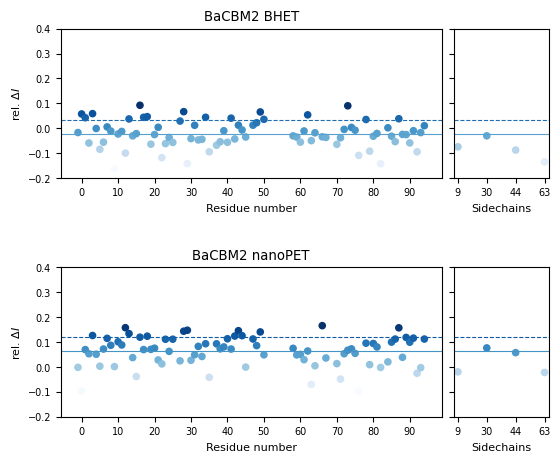

In [33]:
# Plot intensity changes
width_mm = 160
width_in = width_mm / 25.4 
height_in = width_in*0.8
    
fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = True, gridspec_kw={'width_ratios': [4, 1]})
fig.subplots_adjust(hspace=0.6)
fig.subplots_adjust(wspace=0.05)

ax[0,0].set_xlabel('Residue number')
ax[1,0].set_xlabel('Residue number')
ax[0,1].set_xlabel('Sidechains')
ax[1,1].set_xlabel('Sidechains')
ax[0,0].set_ylim((-0.2,0.4))

plot_deltaI(df_Ba_free, df_Ba_BHET, ax[0,0], 'BaCBM2 BHET')
plot_deltaI_sc(df_Ba_free, df_Ba_BHET, df_Ba_free_SC, df_Ba_BHET_SC, ax[0,1])
plot_deltaI(df_Ba_free, df_Ba_nPET, ax[1,0], 'BaCBM2 nanoPET')
plot_deltaI_sc(df_Ba_free, df_Ba_nPET, df_Ba_free_SC, df_Ba_nPET_SC, ax[1,1])
plt.savefig('Plots/BaCBM2_intensity_sc.svg', bbox_inches='tight')

## Linewidths
NB: linewidths are only estimated in CCPN, not sure how well that works. Not published, not checked. 

In [36]:
def plot_deltaLW(dfP, dfPL, ax, label):
    df, std, avg = calc_deltaI(dfP, dfPL)
    df = df.replace([np.inf, -np.inf], np.nan).dropna()

    x = df['res']
    y = df['deltaLW_pct']
    std = std[5]
    avg = avg[5]

    res_above_avg_std = x[y < (avg - std)].tolist()
    res_above_avg = x[y > avg].tolist()

        #Pymol show sticks:
    print(f"\n------------ Relative linewidth change ------------------")
    print(f"Average deltaI: {avg:.4f}")
    print(f"Std Dev:     {std:.4f}")

    print("Residues above average + std:")
    print(res_above_avg_std)
    print("\nPyMOL commands:")
    print("select high_csp_std_" + label + ", resi " + "+".join(map(str, res_above_avg_std)) + "\n")

    #color map
    cmap = plt.get_cmap("Purples_r")
    #define y range for color map
    norm = mcolors.Normalize(vmin=y.min(), vmax=y.max())
    colors = cmap(norm(y))

    #pymol coloring
    rgb_colors = {}
    for resi, value in zip(x, y):
        r, g, b, _ = cmap(norm(value))
        rgb_colors[int(resi)] = (r, g, b)

    label = label.replace(' ', '_')
    filename = f"pymol_csp_i_lw/LW_pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}_l\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}_l\n")

        f.write(f"color white, {label}_l\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}_l"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label}_l and resi {resi}\n"
            )

        f.write(f"select high_{label}_l, {label}_l and resi {'+'.join(map(str, res_above_avg))}\n")
        f.write(f"select high_std_{label}_l, {label}_l and resi {'+'.join(map(str, res_above_avg_std))}\n")
        
    label = label.replace('_', ' ')

    ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8)
    ax.axhline(avg-std, color = cmap(norm(avg-std)), linewidth = 0.8, linestyle = '--')
    ax.scatter(x, y, c= colors, alpha = 1, s = 20)
    ax.set_ylabel('rel. $\Delta LW$')
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_title(label = label)

def plot_deltaLW_sc(dfP, dfPL, dfP_sc, dfPL_sc, ax):
    cmap, norm, colors, avg, std = get_colors_int(dfP, dfPL, -1, "Purples_r")
    df, std_sc, avg_sc = calc_deltaI(dfP_sc, dfPL_sc)
    y = df['deltaLW_pct']
    x = df['res']
    
    ax.axhline(avg, color = cmap(norm(avg)), linewidth = 0.8)
    ax.axhline(avg-std, color = cmap(norm(avg-std)), linewidth = 0.8, linestyle = '--')
    ax.scatter(x, y, c= cmap(norm(y)), alpha = 1, s = 20)



------------ Relative linewidth change ------------------
Average deltaI: 0.0002
Std Dev:     0.0903
Residues above average + std:
[-1, 16, 25, 27, 40, 41, 73, 78]

PyMOL commands:
select high_csp_std_BaCBM2 BHET, resi -1+16+25+27+40+41+73+78


------------ Relative linewidth change ------------------
Average deltaI: 0.0012
Std Dev:     0.0791
Residues above average + std:
[18, 20, 25, 27, 28, 29, 41, 47, 81, 86]

PyMOL commands:
select high_csp_std_BaCBM2 nanoPET, resi 18+20+25+27+28+29+41+47+81+86



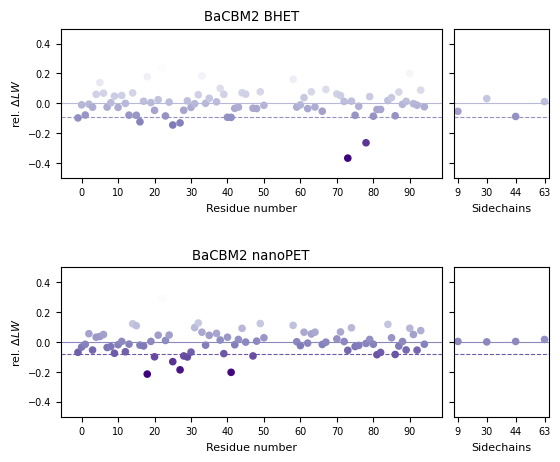

In [37]:
width_mm = 160
width_in = width_mm / 25.4 
height_in = width_in*0.8
    
fig, ax = plt.subplots(2, 2, figsize =((width_in,height_in)), sharey = True, gridspec_kw={'width_ratios': [4, 1]})
fig.subplots_adjust(hspace=0.6)
fig.subplots_adjust(wspace=0.05)

ax[0,0].set_xlabel('Residue number')
ax[1,0].set_xlabel('Residue number')
ax[0,1].set_xlabel('Sidechains')
ax[1,1].set_xlabel('Sidechains')
ax[0,0].set_ylim((-0.5,0.5))

plot_deltaLW(df_Ba_free, df_Ba_BHET, ax[0,0], 'BaCBM2 BHET')
plot_deltaLW_sc(df_Ba_free, df_Ba_BHET, df_Ba_free_SC, df_Ba_BHET_SC, ax[0,1])
plot_deltaLW(df_Ba_free, df_Ba_nPET, ax[1,0], 'BaCBM2 nanoPET')
plot_deltaLW_sc(df_Ba_free, df_Ba_nPET, df_Ba_free_SC, df_Ba_nPET_SC, ax[1,1])
plt.savefig('Plots/BaCBM2_LW_sc.svg', bbox_inches='tight')

## Pymol scripts sidechains
Writes scripts for coloring in pymol (folder: pymol_csp_i_lw)

In [38]:
# pymol colors sidechains

#CSP colors:
def pymol_sc_CSP(df, df_sc, label, remove_first=False):
    cmap, norm, colors, avg, std = get_colors(df, remove_first)
    y = df_sc['DeltaDelta']
    x = df_sc['residue']

    rgb_colors = {}
    for resi, value in zip(x, y):
        r, g, b, _ = cmap(norm(value))
        rgb_colors[int(resi)] = (r, g, b)
    
    filename = f"pymol_csp_i_lw/SC_pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}\n")

        f.write(f"color white, {label}\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label} and resi {resi}\n"
            )

#int and LW colors:
def pymol_sc_int(dfP, dfPL, dfP_sc, dfPL_sc, label, index):
    if index == -1:
        colormap = 'Purples_r'
    elif index == -5:
        colormap = 'Blues'
    cmap, norm, colors, avg, std = get_colors_int(dfP, dfPL, index, colormap)
    
    df, std_sc, avg_sc = calc_deltaI(dfP_sc, dfPL_sc)
    y = df.iloc[:,index]
    x = df['res']

    rgb_colors = {}
    for resi, value in zip(x, y):
        r, g, b, _ = cmap(norm(value))
        rgb_colors[int(resi)] = (r, g, b)

    
    filename = f"pymol_csp_i_lw/SC_pymol_colors_{label}.pml"
    with open(filename, "w") as f:
        if 'Sc' in label:
            f.write(f"set_name fold_sccbm2_model_0, {label}\n")
        elif 'Ba' in label: 
            f.write(f"set_name fold_bacbm2_model_0, {label}\n")
        

        f.write(f"color white, {label}\n")
        for resi, (r, g, b) in rgb_colors.items():
            color_name = f"c_{resi}_{label}"
    
            f.write(
                f"set_color {color_name}, [{r:.4f}, {g:.4f}, {b:.4f}]\n"
            )
            f.write(
                f"color {color_name}, {label} and resi {resi}\n"
            )


In [39]:
#CSPs
labels = ['BHET_Ba', 'nanoPET_Ba']
seq_corr = [7, 7]

CSP_paths = ['CCPN_CSP/Data/BHET_ccpnTable.xlsx', 
             'CCPN_CSP/Data/nanoPET_ccpnTable.xlsx'
            ]

CSP_paths_SC = ['CCPN_CSP/Data/SC_BHET_ccpnTable.xlsx', 
             'CCPN_CSP/Data/SC_nanoPET_ccpnTable.xlsx'
            ]

dfs_CSP = []
for path, corr in zip(CSP_paths, seq_corr):
    df = get_CSP(path, corr)
    dfs_CSP.append(df)

dfs_CSP_SC = []
for path in CSP_paths_SC:
    df = get_CSP_sc(path)
    dfs_CSP_SC.append(df)


for df, df_sc, i, label in zip(dfs_CSP, dfs_CSP_SC, seq_corr, labels):
    if i == 3:
        pymol_sc_CSP(df, df_sc, label, remove_first=False)
    elif i == 7:
        pymol_sc_CSP(df, df_sc, label, remove_first=True)



In [40]:
#int, LWs:
int_lw_dfs_P = [df_Ba_free, df_Ba_free]  #dfP
int_lw_dfs_PL = [df_Ba_BHET, df_Ba_nPET]  #dfPL
int_lw_dfs_P_SC = [df_Ba_free_SC, df_Ba_free_SC]  #dfP_sc
int_lw_dfs_PL_SC = [df_Ba_BHET_SC, df_Ba_nPET_SC]  #dfPL_SC

labels = ['BHET_Ba', 'nanoPET_Ba']

for dfP, dfPL, dfP_sc, dfPL_sc, label in zip(int_lw_dfs_P, int_lw_dfs_PL, int_lw_dfs_P_SC, int_lw_dfs_PL_SC, labels):
    lab = label + '_int'
    index = -5
    pymol_sc_int(dfP, dfPL, dfP_sc, dfPL_sc, lab, index)

    lab = label + '_LW'
    index = -1
    pymol_sc_int(dfP, dfPL, dfP_sc, dfPL_sc, lab, index)
